# Step 1: Understand Your Data
# (A) Load and preview the dataset.
# (B) Check data types, unique values, and presence of nulls.
# (C) Understand which variables are categorical and which are numerical.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
#   Load and preview the dataset.

In [19]:
FP = r"C:\Users\yaash\US_Customer_Insights_Dataset.csv"

In [20]:
df = pd.read_csv(FP)

In [21]:
df.head(1)

,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
0,CUST10319,Scott Perez,Florida,High School,Non-Binary,47,Yes,1,9/19/21,9/2/24,1281.74,332


In [22]:
df.shape

(10675, 12)

In [23]:
df.describe

<bound method NDFrame.describe of       CustomerID                Name       State    Education      Gender  \
0      CUST10319         Scott Perez     Florida  High School  Non-Binary   
1      CUST10695     Jennifer Burton  Washington       Master        Male   
2      CUST10297     Michelle Rogers     Arizona       Master      Female   
3      CUST10103    Brooke Hendricks       Texas       Master        Male   
4      CUST10219         Karen Johns       Texas  High School      Female   
...          ...                 ...         ...          ...         ...   
10670  CUST10833        Steven Burns     Georgia          PhD      Female   
10671  CUST10620         Jesse Pratt       Texas       Master        Male   
10672  CUST10449          John Lloyd     Arizona       Master  Non-Binary   
10673  CUST10020  Christopher Sparks     Florida     Bachelor      Female   
10674  CUST10267    Melissa Marshall     Arizona    Associate  Non-Binary   

       Age Married  NumPets JoinDate Tran

In [77]:
#  Check data types, unique values, and presence of nulls.

In [24]:
df.nunique()

CustomerID                  1000
Name                         990
State                         10
Education                      5
Gender                         3
Age                           63
Married                        2
NumPets                        5
JoinDate                     731
TransactionDate             1605
MonthlySpend                9843
DaysSinceLastInteraction    1605
dtype: int64

In [25]:
df.isnull().sum()

CustomerID                  0
Name                        0
State                       0
Education                   0
Gender                      0
Age                         0
Married                     0
NumPets                     0
JoinDate                    0
TransactionDate             0
MonthlySpend                0
DaysSinceLastInteraction    0
dtype: int64

In [76]:
#  Understand which variables are categorical and which are numerical.

In [26]:
print("Numerical Columns:")
print(df.select_dtypes(include="number").columns.tolist())


print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical Columns:
['Age', 'NumPets', 'MonthlySpend', 'DaysSinceLastInteraction']

Categorical Columns:
['CustomerID', 'Name', 'State', 'Education', 'Gender', 'Married', 'JoinDate', 'TransactionDate']


# Step 2: Descriptive Statistics

# (A) Mean, median, std dev for Age, MonthlySpend, DaysSinceLastInteraction
# (B) Mode for categorical variables: Gender, Education, Married


In [75]:
#   Mean, median, std dev for Age, MonthlySpend, DaysSinceLastInteraction

In [29]:
print("Mean:")
print(df[["Age", "MonthlySpend", "DaysSinceLastInteraction"]].mean())

Mean:
Age                          49.474567
MonthlySpend                331.610315
DaysSinceLastInteraction    538.469883
dtype: float64


In [30]:
print("\nMedian:")
print(df[["Age", "MonthlySpend", "DaysSinceLastInteraction"]].median())


Median:
Age                          49.00
MonthlySpend                282.11
DaysSinceLastInteraction    445.00
dtype: float64


In [31]:
print("\nStandard Deviation:")
print(df[["Age", "MonthlySpend", "DaysSinceLastInteraction"]].std())


Standard Deviation:
Age                          18.221365
MonthlySpend                225.799253
DaysSinceLastInteraction    398.766747
dtype: float64


In [74]:
#  Mode for categorical variables: Gender, Education, Married

In [36]:
categorical_columns = ["Gender","Education","Married"]

for column in categorical_columns:
    print(f"\nMode of {column}:")
    print(df[column].mode()[0])


Mode of Gender:
Male

Mode of Education:
Master

Mode of Married:
No


# Step 3: Data Visualization

# (A) Plot histograms and boxplots for Age, MonthlySpend
# (B) Create a bar chart for Gender, Education, State
# (C) Scatterplot: Age vs MonthlySpend
# (D) KDE: Spending behavior by education level or marital status


In [73]:
#  Plot histograms and boxplots for Age

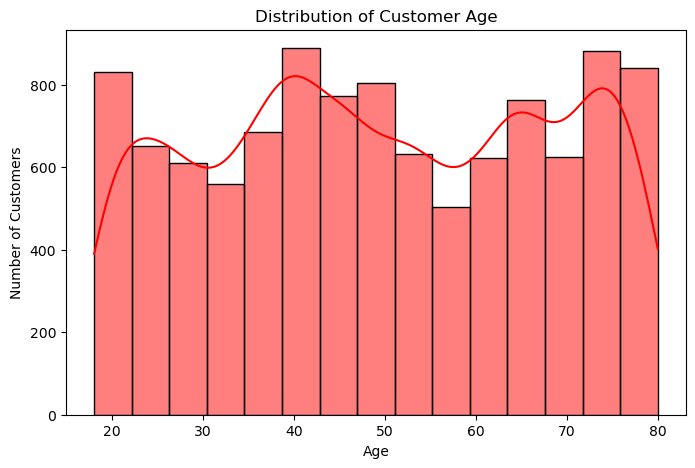

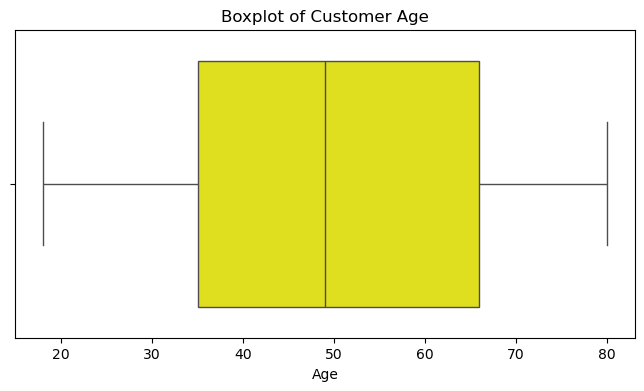

In [54]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=15, color="red", kde=True)

plt.title("Distribution of Customer Age")
plt.ylabel("Number of Customers")
plt.xlabel("Age")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Age"],color="yellow")

plt.title("Boxplot of Customer Age")
plt.xlabel("Age")
plt.show()

In [72]:
#  Plot histograms and boxplots for MonthlySpend

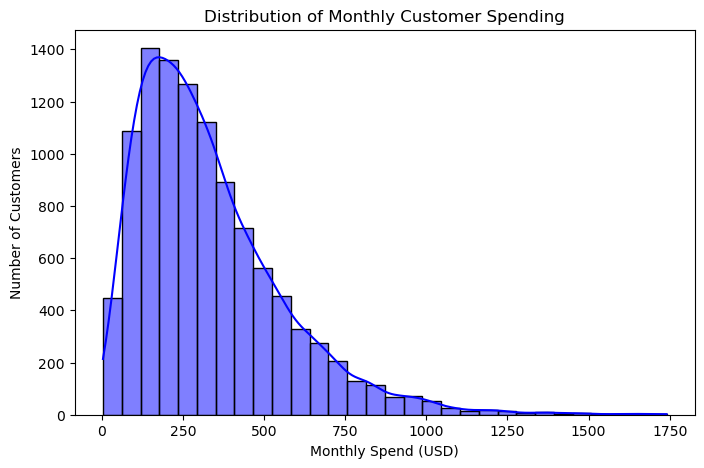

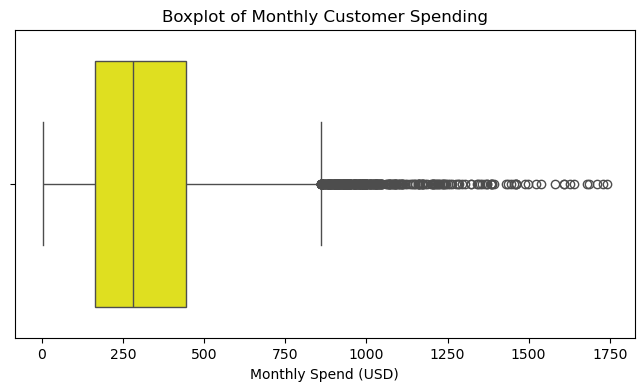

In [62]:
plt.figure(figsize=(8, 5))
sns.histplot(df["MonthlySpend"], bins=30, color="blue", kde=True)

plt.title("Distribution of Monthly Customer Spending")
plt.xlabel("Monthly Spend (USD)")
plt.ylabel("Number of Customers")
plt.show()


plt.figure(figsize=(8, 4))
sns.boxplot(x=df["MonthlySpend"],color="yellow")

plt.title("Boxplot of Monthly Customer Spending")
plt.xlabel("Monthly Spend (USD)")
plt.show()

In [71]:
#  Create a bar chart for Gender, Education, State

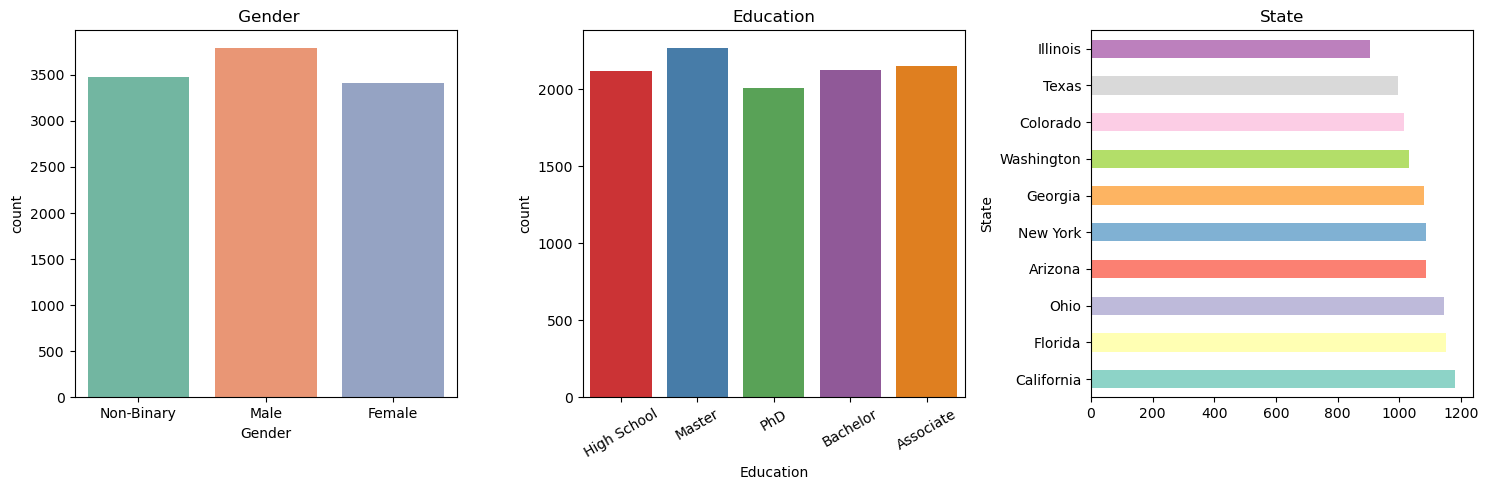

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title(" Gender")

sns.countplot(data=df, x="Education", hue="Education", palette="Set1", legend=False, ax=axes[1])
axes[1].set_title("Education")
axes[1].tick_params(axis="x", rotation=30)

state_counts = df["State"].value_counts()
state_counts.plot(kind="barh", color=sns.color_palette("Set3", len(state_counts)), ax=axes[2])
axes[2].set_title("State")

plt.tight_layout()
plt.show()

In [99]:
#  Scatterplot: Age vs MonthlySpend

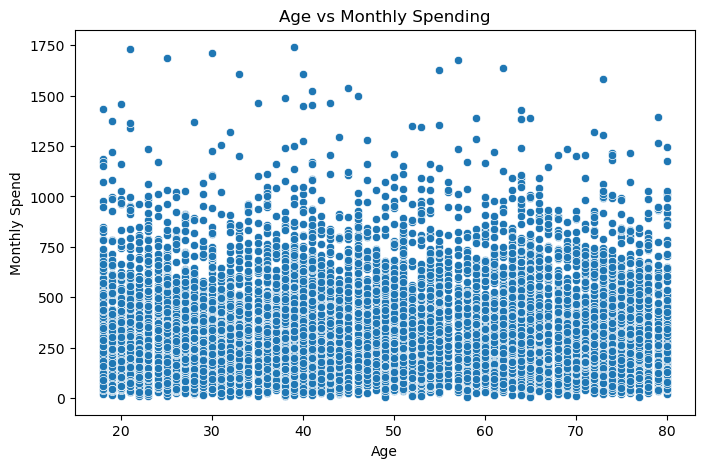

In [93]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x="Age",y="MonthlySpend")

plt.title("Age vs Monthly Spending")
plt.xlabel("Age")
plt.ylabel("Monthly Spend")
plt.show()

In [91]:
#   KDE: Spending behavior by education level 

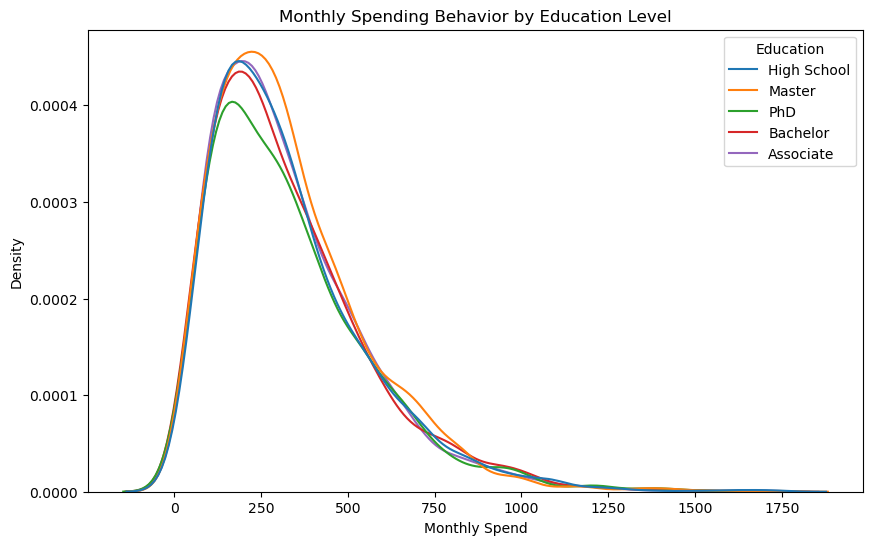

In [101]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x="MonthlySpend",hue="Education",fill=False)

plt.title("Monthly Spending Behavior by Education Level")
plt.xlabel("Monthly Spend")
plt.ylabel("Density")
plt.show()

In [103]:
#   KDE: Spending behavior by Married status

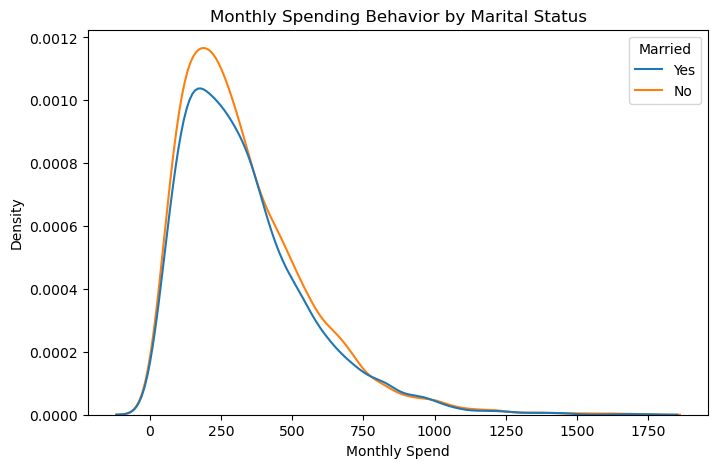

In [104]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df,x="MonthlySpend",hue="Married",fill=False)

plt.title("Monthly Spending Behavior by Marital Status")
plt.xlabel("Monthly Spend")
plt.ylabel("Density")
plt.show()

# Step 4: Bivariate Analysis
# (A) Correlation matrix (numeric variables)
# (B) Crosstab of Gender vs Married
# (C) Grouped stats: average MonthlySpend by State, Education, Gender

In [105]:
# Correlation matrix (numeric variables)

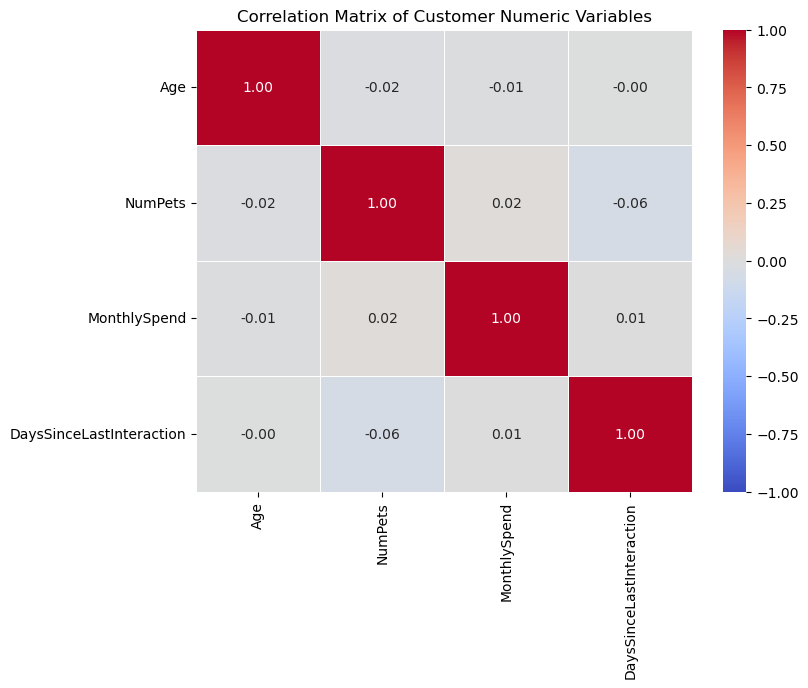

In [118]:
numeric_columns = ["Age","NumPets","MonthlySpend","DaysSinceLastInteraction"]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)

plt.title("Correlation Matrix of Customer Numeric Variables")
plt.show()

In [132]:
# Crosstab of Gender vs Married

In [135]:
gender_married = pd.crosstab(df["Gender"],df["Married"])

gender_married

Married,No,Yes
Gender,,
Female,1797,1616
Male,1892,1899
Non-Binary,1894,1577


In [134]:
#  Grouped stats: average MonthlySpend by State, Education, Gender

In [133]:
print("Average MonthlySpend by State:")
print(df.groupby("State")["MonthlySpend"].mean().round(2))

print("\nAverage MonthlySpend by Education:")
print(df.groupby("Education")["MonthlySpend"].mean().round(2))

print("\nAverage MonthlySpend by Gender:")
print(df.groupby("Gender")["MonthlySpend"].mean().round(2))

Average MonthlySpend by State:
State
Arizona       341.49
California    339.18
Colorado      323.08
Florida       327.70
Georgia       328.35
Illinois      332.59
New York      332.15
Ohio          340.19
Texas         319.51
Washington    329.44
Name: MonthlySpend, dtype: float64

Average MonthlySpend by Education:
Education
Associate      327.88
Bachelor       331.88
High School    332.22
Master         334.25
PhD            331.69
Name: MonthlySpend, dtype: float64

Average MonthlySpend by Gender:
Gender
Female        331.36
Male          333.17
Non-Binary    330.15
Name: MonthlySpend, dtype: float64


#  Step 5: Formulate Hypotheses

In [162]:
male_spend = df[df["Gender"] == "Male"]["MonthlySpend"]
female_spend = df[df["Gender"] == "Female"]["MonthlySpend"]

t_stat, p_value = ttest_ind(male_spend,female_spend,equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Males and females have significantly different average spending.")
else:
    print("Fail to reject H0: No significant difference in average spending.")

T-statistic: 0.3391303706925083
P-value: 0.7345215220030699
Fail to reject H0: No significant difference in average spending.


In [151]:
education_groups = [
    group["MonthlySpend"].values
    for name, group in df.groupby("Education")]

f_stat, p_value = f_oneway(*education_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Education level has a significant relationship with MonthlySpend.")
else:
    print("Fail to reject H0: No significant difference in MonthlySpend across education levels.")

F-statistic: 0.22880668673709165
P-value: 0.922359467759936
Fail to reject H0: No significant difference in MonthlySpend across education levels.


In [163]:
pet_table = pd.crosstab(df["Married"],df["NumPets"])

pet_table

chi2, p_value, dof, expected = chi2_contingency(pet_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

if p_value < 0.05:
    print("Reject H0: Marital status is significantly related to pet ownership.")
else:
    print("Fail to reject H0: No significant relationship between marital status and pet ownership.")

Chi-square statistic: 177.63953668537033
P-value: 2.3957232932397494e-37
Degrees of freedom: 4
Reject H0: Marital status is significantly related to pet ownership.


In [168]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(df["Age"],df["DaysSinceLastInteraction"])

print("Correlation:", correlation)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Age and interaction recency have a significant relationship.")
else:
    print("Fail to reject H0: No significant relationship between Age and interaction recency.")

Correlation: -0.003970230104955045
P-value: 0.6816905437300954
Fail to reject H0: No significant relationship between Age and interaction recency.


In [171]:
from scipy.stats import f_oneway

state_groups = [group["MonthlySpend"].values
    for name, group in df.groupby("State")]

f_stat, p_value = f_oneway(*state_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Average MonthlySpend varies significantly across states.")
else:
    print("Fail to reject H0: No significant difference in MonthlySpend across states.")

F-statistic: 1.117842364087718
P-value: 0.34571886479238273
Fail to reject H0: No significant difference in MonthlySpend across states.


# Step 6: Run Hypothesis Tests

# (A) Define null and alternate hypotheses
# (B) Choose test based on data types
# (C) Check assumptions: normality, independence, homogeneity of variance
# (D) Interpret p-values and confidence intervals


In [175]:
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("\n=== TEST 1: Do males and females spend differently? ===")

# Select only Male and Female customers
male = df[df["Gender"] == "Male"]["MonthlySpend"].dropna()
female = df[df["Gender"] == "Female"]["MonthlySpend"].dropna()

# -----------------------------
# Check Normality
# -----------------------------
def check_normality(data, group_name):
    sample = data.sample(min(5000, len(data)), random_state=42)
    stat, p = stats.shapiro(sample)

    print(f"{group_name} normality p-value:", p)

    if p > 0.05:
        print(f"{group_name}: Approximately normal")
        return True
    else:
        print(f"{group_name}: Not normally distributed")
        return False


# -----------------------------
# Check Homogeneity of Variance
# -----------------------------
def check_variance(group1, group2):
    stat, p = stats.levene(group1, group2)

    print("Levene's test p-value:", p)

    if p > 0.05:
        print("Variances are equal")
        return True
    else:
        print("Variances are not equal")
        return False


# -----------------------------
# Run Assumption Tests
# -----------------------------
normal_male = check_normality(male, "Male")
normal_female = check_normality(female, "Female")

equal_var = check_variance(male, female)


# -----------------------------
# Choose Statistical Test
# -----------------------------
if (normal_male and normal_female) or min(len(male), len(female)) > 30:

    t_stat, p_value = stats.ttest_ind(male,female,equal_var=equal_var)

    if equal_var:
        test_name = "Student's Independent t-test"
    else:
        test_name = "Welch's t-test"

else:
    t_stat, p_value = stats.mannwhitneyu(male,female,alternative="two-sided")
    test_name = "Mann-Whitney U test"

# -----------------------------
# Results
# -----------------------------
print("\nTest Used:", test_name)
print("Test Statistic:", t_stat)
print("P-value:", p_value)


# -----------------------------
# Final Decision
# -----------------------------
if p_value < 0.05:
    print("Decision: Reject H0")
    print("Conclusion: Male and female customers have significantly different spending.")
else:
    print("Decision: Fail to reject H0")
    print("Conclusion: There is no significant difference in spending between males and females.")


=== TEST 1: Do males and females spend differently? ===
Male normality p-value: 6.19066173283907e-45
Male: Not normally distributed
Female normality p-value: 1.8607750491112584e-42
Female: Not normally distributed
Levene's test p-value: 0.7218295518516542
Variances are equal

Test Used: Student's Independent t-test
Test Statistic: 0.3391730320232445
P-value: 0.7344892727022859
Decision: Fail to reject H0
Conclusion: There is no significant difference in spending between males and females.


In [179]:
ALPHA = 0.05
# =====================================================
# Helper function for decision
# =====================================================
def decision(p):
    if p < ALPHA:
        return "Reject H0"
    else:
        return "Fail to reject H0"


# =====================================================
# TEST 2: Education vs MonthlySpend
# One-way ANOVA
# =====================================================
print("\n=== TEST 2: Education vs MonthlySpend ===")
groups = [
    group["MonthlySpend"].dropna()
    for name, group in df.groupby("Education") ]

f_stat, p = stats.f_oneway(*groups)

print("F-statistic:", round(f_stat, 3))
print("P-value:", round(p, 4))
print("Decision:", decision(p))

if p < ALPHA:
    print("Conclusion: Education level has a significant effect on spending.")
    
    tukey = pairwise_tukeyhsd(
        df["MonthlySpend"].dropna(),
        df.loc[df["MonthlySpend"].notna(), "Education"]
    )
    print("\nTukey HSD:")
    print(tukey)

else:
    print("Conclusion: Education level does not have a significant effect on spending.")


=== TEST 2: Education vs MonthlySpend ===
F-statistic: 0.229
P-value: 0.9224
Decision: Fail to reject H0
Conclusion: Education level does not have a significant effect on spending.


In [182]:
# =====================================================
# TEST 3: Married vs Pet Ownership
# Chi-square Test
# =====================================================

print("\n=== TEST 3: Married vs Pet Ownership ===")

# Create pet category
df["Pet_Category"] = np.where(
    df["NumPets"] == 0,
    "No Pets",
    "Has Pets"
)

# Create table
table = pd.crosstab(
    df["Married"],
    df["Pet_Category"]
)

print("\nContingency Table:")
print(table)

# Chi-square test
chi2, p, dof, expected = stats.chi2_contingency(table)

print("\nChi-square:", round(chi2, 3))
print("P-value:", round(p, 4))
print("Decision:", decision(p))

if p < ALPHA:
    print("Conclusion: Marital status and pet ownership are significantly related.")
else:
    print("Conclusion: Marital status and pet ownership are not significantly related.")


=== TEST 3: Married vs Pet Ownership ===

Contingency Table:
Pet_Category  Has Pets  No Pets
Married                        
No                3744     1839
Yes               3887     1205

Chi-square: 111.928
P-value: 0.0
Decision: Reject H0
Conclusion: Marital status and pet ownership are significantly related.


In [183]:
# =====================================================
# TEST 4: Age vs DaysSinceLastInteraction
# Correlation
# =====================================================

print("\n=== TEST 4: Age vs DaysSinceLastInteraction ===")

data = df[
    ["Age", "DaysSinceLastInteraction"]
].dropna()

# Pearson correlation
r, p = stats.pearsonr(
    data["Age"],
    data["DaysSinceLastInteraction"]
)

print("Correlation:", round(r, 3))
print("P-value:", round(p, 4))
print("Decision:", decision(p))

if p < ALPHA:

    if r > 0:
        print("Conclusion: Older customers tend to be less active.")
    else:
        print("Conclusion: Older customers tend to be more active.")

else:
    print("Conclusion: There is no significant relationship between age and activity.")




=== TEST 4: Age vs DaysSinceLastInteraction ===
Correlation: -0.004
P-value: 0.6817
Decision: Fail to reject H0
Conclusion: There is no significant relationship between age and activity.


In [184]:
# =====================================================
# TEST 5: State vs MonthlySpend
# One-way ANOVA
# =====================================================

print("\n=== TEST 5: State vs MonthlySpend ===")

groups = [
    group["MonthlySpend"].dropna()
    for name, group in df.groupby("State")
]

f_stat, p = stats.f_oneway(*groups)

print("F-statistic:", round(f_stat, 3))
print("P-value:", round(p, 4))
print("Decision:", decision(p))

if p < ALPHA:
    print("Conclusion: Spending differs significantly across states.")

    tukey = pairwise_tukeyhsd(
        df["MonthlySpend"].dropna(),
        df.loc[df["MonthlySpend"].notna(), "State"]
    )
    print("\nTukey HSD:")
    print(tukey)

else:
    print("Conclusion: There is no significant difference in spending across states.")


=== TEST 5: State vs MonthlySpend ===
F-statistic: 1.118
P-value: 0.3457
Decision: Fail to reject H0
Conclusion: There is no significant difference in spending across states.


# Step 7: Present Business Insights

# (A) “Customers with Master’s degrees spend 18% more per month on average.”
# (B)“Non-married customers with pets show the highest re-engagement potential.”
# (C)“Florida and Texas show the greatest variability in spending — personalize your campaigns by state.”

In [185]:
print("========== BUSINESS INSIGHTS ==========")


# 1. Gender and Spending
gender_spend = df.groupby("Gender")["MonthlySpend"].mean()

highest_gender = gender_spend.idxmax()
highest_gender_spend = gender_spend.max()

print("\n1. Gender Spending:")
print(
    f"{highest_gender} customers have the highest "
    f"average monthly spending of ${highest_gender_spend:.2f}.")

========== BUSINESS INSIGHTS ==========

1. Gender Spending:
Male customers have the highest average monthly spending of $333.17.


In [188]:
# 2. Education and Spending
education_spend = (
    df.groupby("Education")["MonthlySpend"]
    .mean()
    .sort_values(ascending=False) )

highest_education = education_spend.index[0]
highest_education_spend = education_spend.iloc[0]

print("\n2. Education Spending:")
print(
    f"Customers with {highest_education} education "
    f"have the highest average monthly spending "
    f"of ${highest_education_spend:.2f}.")


2. Education Spending:
Customers with Master education have the highest average monthly spending of $334.25.


In [186]:
# 3. State and Spending
state_spend = (
    df.groupby("State")["MonthlySpend"]
    .mean()
    .sort_values(ascending=False) )

highest_state = state_spend.index[0]
highest_state_spend = state_spend.iloc[0]

print("\n3. State Spending:")
print(
    f"{highest_state} has the highest average "
    f"monthly customer spending of ${highest_state_spend:.2f}.")


3. State Spending:
Arizona has the highest average monthly customer spending of $341.49.


In [187]:
# 4. Customer Engagement
engagement = (df.groupby("Gender")["DaysSinceLastInteraction"].mean().sort_values())

most_active_gender = engagement.index[0]

print("\n4. Customer Engagement:")
print(f"{most_active_gender} customers are the most recently "
     f"engaged based on the lowest average days since "
     f"last interaction.")


4. Customer Engagement:
Non-Binary customers are the most recently engaged based on the lowest average days since last interaction.


In [189]:
# 5. Pet Ownership and Marital Status
pet_analysis = pd.crosstab(df["Married"],df["Pet_Category"],normalize="index") * 100

print("\n5. Pet Ownership:")
print(
    "Compare married and non-married customers by pet "
    "ownership to identify the group with greater "
    "engagement or targeting potential.")

print("\nPet Ownership Percentage:")
print(pet_analysis.round(2))


5. Pet Ownership:
Compare married and non-married customers by pet ownership to identify the group with greater engagement or targeting potential.

Pet Ownership Percentage:
Pet_Category  Has Pets  No Pets
Married                        
No               67.06    32.94
Yes              76.34    23.66
